# Compatibility fix for the Streamlit app

The model files previously saved from this notebook were created with scikit-learn 1.6.1, while the local Streamlit environment uses scikit-learn 1.8.0. Pickled scikit-learn pipelines are not guaranteed to work across versions.

**Before exporting the models for VS Code:** run the installation cell below, restart the Colab runtime (`Runtime` → `Restart session`), then choose `Runtime` → `Run all`. When prompted, upload `MLDST_Final_Cleaned.csv`. This reruns the notebook under scikit-learn 1.8.0 so the exported pipelines match the local app environment.

The evaluation workflow and model settings are otherwise unchanged. Because the models are retrained, verify the final evaluation cells after the notebook finishes.

In [ ]:
# Install the same scikit-learn version used by the local Streamlit environment.
%pip install -q --upgrade scikit-learn==1.8.0

import sklearn
print('Installed scikit-learn version:', sklearn.__version__)
print('Now restart the Colab runtime, then use Runtime > Run all.')

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 63.5 MB/s eta 0:00:00
Installed scikit-learn version: 1.8.0
Now restart the Colab runtime, then use Runtime > Run all.


In [ ]:
# ============================================
# MACHINE LEARNING FINAL PROJECT
# The Rising Cost of Food:
# Exploring Regional Food Price Changes in the Philippines
# ============================================

# Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Machine Learning
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

# Regression Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Evaluation Metrics
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")
import sklearn
print("Scikit-learn version:", sklearn.__version__)


Libraries imported successfully!
Scikit-learn version: 1.8.0


In [ ]:
# Upload the dataset

from google.colab import files

uploaded = files.upload()

Saving MLDST_Final_Cleaned.csv to MLDST_Final_Cleaned.csv


In [ ]:
# Load the dataset

df = pd.read_csv("MLDST_Final_Cleaned.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (12768, 9)


In [ ]:
# Inspect the dataset

print("Column names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nFirst 5 rows:")
display(df.head())

Column names:
['Geolocation', 'Commodity', 'Commodity_Code', 'Commodity_Name', 'Date', 'Year', 'Month', 'Month_Name', 'CPI']

Data types:
Geolocation        object
Commodity          object
Commodity_Code     object
Commodity_Name     object
Date               object
Year                int64
Month               int64
Month_Name         object
CPI               float64
dtype: object

First 5 rows:


,Geolocation,Commodity,Commodity_Code,Commodity_Name,Date,Year,Month,Month_Name,CPI
0,Bangsamoro Autonomous Region in Muslim Mindana...,"01.1.4 - Milk, other dairy products and eggs (ND)",01.1.4,Dairy & Eggs,2018-01-01,2018,1,Jan,98.8
1,Bangsamoro Autonomous Region in Muslim Mindana...,"01.1.4 - Milk, other dairy products and eggs (ND)",01.1.4,Dairy & Eggs,2018-02-01,2018,2,Feb,99.7
2,Bangsamoro Autonomous Region in Muslim Mindana...,"01.1.4 - Milk, other dairy products and eggs (ND)",01.1.4,Dairy & Eggs,2018-03-01,2018,3,Mar,99.0
3,Bangsamoro Autonomous Region in Muslim Mindana...,"01.1.4 - Milk, other dairy products and eggs (ND)",01.1.4,Dairy & Eggs,2018-04-01,2018,4,Apr,98.0
4,Bangsamoro Autonomous Region in Muslim Mindana...,"01.1.4 - Milk, other dairy products and eggs (ND)",01.1.4,Dairy & Eggs,2018-05-01,2018,5,May,98.8


In [ ]:
# Check for missing values

print("Missing values per column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())

# Check for duplicate rows

print("\nNumber of duplicate rows:", df.duplicated().sum())

Missing values per column:
Geolocation       0
Commodity         0
Commodity_Code    0
Commodity_Name    0
Date              0
Year              0
Month             0
Month_Name        0
CPI               0
dtype: int64

Total missing values: 0

Number of duplicate rows: 0


In [ ]:
# Check the date column

print("Date data type before conversion:")
print(df["Date"].dtype)

# Convert Date to datetime
df["Date"] = pd.to_datetime(df["Date"])

print("\nDate data type after conversion:")
print(df["Date"].dtype)

print("\nEarliest date:")
print(df["Date"].min())

print("\nLatest date:")
print(df["Date"].max())

print("\nNumber of unique dates:")
print(df["Date"].nunique())

Date data type before conversion:
object

Date data type after conversion:
datetime64[ns]

Earliest date:
2018-01-01 00:00:00

Latest date:
2025-12-01 00:00:00

Number of unique dates:
96


In [ ]:
# Sort the dataset chronologically
df = df.sort_values(
    ["Geolocation", "Commodity_Code", "Date"]
).reset_index(drop=True)

# Check the number of observations for each
# Geolocation + Commodity combination

group_counts = (
    df.groupby(["Geolocation", "Commodity_Code"])
      .size()
      .describe()
)

print("Observations per Geolocation + Commodity group:")
print(group_counts)

print("\nNumber of Geolocation + Commodity groups:")
print(
    df.groupby(["Geolocation", "Commodity_Code"])
      .ngroups
)

Observations per Geolocation + Commodity group:
count    133.0
mean      96.0
std        0.0
min       96.0
25%       96.0
50%       96.0
75%       96.0
max       96.0
dtype: float64

Number of Geolocation + Commodity groups:
133


In [ ]:
# Check for duplicate months within each
# Geolocation + Commodity combination

duplicate_months = df.duplicated(
    subset=["Geolocation", "Commodity_Code", "Date"]
).sum()

print("Duplicate Geolocation + Commodity + Date records:", duplicate_months)

Duplicate Geolocation + Commodity + Date records: 0


In [ ]:
# Check for missing monthly observations within each group

groups_with_gaps = []

for (geo, commodity), group in df.groupby(
    ["Geolocation", "Commodity_Code"]
):
    dates = group["Date"].sort_values()

    expected_dates = pd.date_range(
        dates.min(),
        dates.max(),
        freq="MS"
    )

    missing_dates = expected_dates.difference(dates)

    if len(missing_dates) > 0:
        groups_with_gaps.append({
            "Geolocation": geo,
            "Commodity_Code": commodity,
            "Missing_Months": len(missing_dates)
        })

gaps_df = pd.DataFrame(groups_with_gaps)

print("Number of groups with missing months:", len(gaps_df))

display(gaps_df.head(10))

Number of groups with missing months: 0


""


In [ ]:
# Create the target variable: next month's CPI
# within each Geolocation + Commodity group

df["Target_CPI"] = (
    df.groupby(
        ["Geolocation", "Commodity_Code"]
    )["CPI"]
    .shift(-1)
)

print("Target_CPI created successfully!")

display(
    df[
        [
            "Geolocation",
            "Commodity_Name",
            "Date",
            "CPI",
            "Target_CPI"
        ]
    ].head(10)
)

Target_CPI created successfully!


,Geolocation,Commodity_Name,Date,CPI,Target_CPI
0,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-01-01,95.9,96.7
1,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-02-01,96.7,97.5
2,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-03-01,97.5,97.8
3,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-04-01,97.8,97.8
4,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-05-01,97.8,100.1
5,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-06-01,100.1,100.0
6,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-07-01,100.0,100.8
7,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-08-01,100.8,103.0
8,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-09-01,103.0,103.1
9,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-10-01,103.1,103.1


In [ ]:
# Check missing Target_CPI values

print("Missing Target_CPI values:")
print(df["Target_CPI"].isnull().sum())

Missing Target_CPI values:
133


In [ ]:
# Remove rows where Target_CPI is missing

df = df.dropna(subset=["Target_CPI"]).reset_index(drop=True)

print("Rows after removing missing Target_CPI:")
print(df.shape)

print("\nRemaining missing Target_CPI:")
print(df["Target_CPI"].isnull().sum())

Rows after removing missing Target_CPI:
(12635, 10)

Remaining missing Target_CPI:
0


In [ ]:
# Create lag features within each Geolocation + Commodity group

group_cols = ["Geolocation", "Commodity_Code"]

df["CPI_Lag_1"] = (
    df.groupby(group_cols)["CPI"].shift(1)
)

df["CPI_Lag_2"] = (
    df.groupby(group_cols)["CPI"].shift(2)
)

df["CPI_Lag_3"] = (
    df.groupby(group_cols)["CPI"].shift(3)
)

print("Lag features created successfully!")

display(
    df[
        [
            "Geolocation",
            "Commodity_Name",
            "Date",
            "CPI",
            "CPI_Lag_1",
            "CPI_Lag_2",
            "CPI_Lag_3",
            "Target_CPI"
        ]
    ].head(10)
)

Lag features created successfully!


,Geolocation,Commodity_Name,Date,CPI,CPI_Lag_1,CPI_Lag_2,CPI_Lag_3,Target_CPI
0,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-01-01,95.9,NaN,NaN,NaN,96.7
1,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-02-01,96.7,95.9,NaN,NaN,97.5
2,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-03-01,97.5,96.7,95.9,NaN,97.8
3,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-04-01,97.8,97.5,96.7,95.9,97.8
4,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-05-01,97.8,97.8,97.5,96.7,100.1
5,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-06-01,100.1,97.8,97.8,97.5,100.0
6,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-07-01,100.0,100.1,97.8,97.8,100.8
7,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-08-01,100.8,100.0,100.1,97.8,103.0
8,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-09-01,103.0,100.8,100.0,100.1,103.1
9,Bangsamoro Autonomous Region in Muslim Mindana...,Food,2018-10-01,103.1,103.0,100.8,100.0,103.1


In [ ]:
# Create CPI change features

df["CPI_Change"] = (
    df["CPI"] - df["CPI_Lag_1"]
)

df["CPI_Pct_Change"] = (
    (df["CPI"] - df["CPI_Lag_1"])
    / df["CPI_Lag_1"]
)

print("CPI change features created successfully!")

display(
    df[
        [
            "Date",
            "CPI",
            "CPI_Lag_1",
            "CPI_Change",
            "CPI_Pct_Change",
            "Target_CPI"
        ]
    ].head(10)
)

CPI change features created successfully!


,Date,CPI,CPI_Lag_1,CPI_Change,CPI_Pct_Change,Target_CPI
0,2018-01-01,95.9,NaN,NaN,NaN,96.7
1,2018-02-01,96.7,95.9,0.8,0.008342,97.5
2,2018-03-01,97.5,96.7,0.8,0.008273,97.8
3,2018-04-01,97.8,97.5,0.3,0.003077,97.8
4,2018-05-01,97.8,97.8,0.0,0.000000,100.1
5,2018-06-01,100.1,97.8,2.3,0.023517,100.0
6,2018-07-01,100.0,100.1,-0.1,-0.000999,100.8
7,2018-08-01,100.8,100.0,0.8,0.008000,103.0
8,2018-09-01,103.0,100.8,2.2,0.021825,103.1
9,2018-10-01,103.1,103.0,0.1,0.000971,103.1


In [ ]:
# Create 3-month rolling features using previous months only

df["CPI_Rolling_Mean_3"] = (
    df.groupby(group_cols)["CPI"]
      .transform(lambda x: x.shift(1).rolling(3).mean())
)

df["CPI_Rolling_Std_3"] = (
    df.groupby(group_cols)["CPI"]
      .transform(lambda x: x.shift(1).rolling(3).std())
)

print("Rolling features created successfully!")

display(
    df[
        [
            "Date",
            "CPI",
            "CPI_Lag_1",
            "CPI_Lag_2",
            "CPI_Lag_3",
            "CPI_Rolling_Mean_3",
            "CPI_Rolling_Std_3",
            "Target_CPI"
        ]
    ].head(10)
)

Rolling features created successfully!


,Date,CPI,CPI_Lag_1,CPI_Lag_2,CPI_Lag_3,CPI_Rolling_Mean_3,CPI_Rolling_Std_3,Target_CPI
0,2018-01-01,95.9,NaN,NaN,NaN,NaN,NaN,96.7
1,2018-02-01,96.7,95.9,NaN,NaN,NaN,NaN,97.5
2,2018-03-01,97.5,96.7,95.9,NaN,NaN,NaN,97.8
3,2018-04-01,97.8,97.5,96.7,95.9,96.700000,0.800000,97.8
4,2018-05-01,97.8,97.8,97.5,96.7,97.333333,0.568624,100.1
5,2018-06-01,100.1,97.8,97.8,97.5,97.700000,0.173205,100.0
6,2018-07-01,100.0,100.1,97.8,97.8,98.566667,1.327906,100.8
7,2018-08-01,100.8,100.0,100.1,97.8,99.300000,1.300000,103.0
8,2018-09-01,103.0,100.8,100.0,100.1,100.300000,0.435890,103.1
9,2018-10-01,103.1,103.0,100.8,100.0,101.266667,1.553491,103.1


In [ ]:
# Create month-based seasonal features

df["Month_Sin"] = np.sin(
    2 * np.pi * df["Month"] / 12
)

df["Month_Cos"] = np.cos(
    2 * np.pi * df["Month"] / 12
)

# Create Philippine weather-season feature

def get_weather_season(month):
    if month in [12, 1, 2]:
        return "Cool_Dry"
    elif month in [3, 4, 5]:
        return "Hot_Dry"
    elif month in [6, 7, 8]:
        return "Rainy"
    else:
        return "Rainy_Transition"

df["Weather_Season"] = df["Month"].apply(
    get_weather_season
)

print("Seasonal features created successfully!")

display(
    df[
        [
            "Date",
            "Month",
            "Month_Sin",
            "Month_Cos",
            "Weather_Season"
        ]
    ].head(15)
)

Seasonal features created successfully!


,Date,Month,Month_Sin,Month_Cos,Weather_Season
0,2018-01-01,1,5.000000e-01,8.660254e-01,Cool_Dry
1,2018-02-01,2,8.660254e-01,5.000000e-01,Cool_Dry
2,2018-03-01,3,1.000000e+00,6.123234e-17,Hot_Dry
3,2018-04-01,4,8.660254e-01,-5.000000e-01,Hot_Dry
4,2018-05-01,5,5.000000e-01,-8.660254e-01,Hot_Dry
5,2018-06-01,6,1.224647e-16,-1.000000e+00,Rainy
6,2018-07-01,7,-5.000000e-01,-8.660254e-01,Rainy
7,2018-08-01,8,-8.660254e-01,-5.000000e-01,Rainy
8,2018-09-01,9,-1.000000e+00,-1.836970e-16,Rainy_Transition
9,2018-10-01,10,-8.660254e-01,5.000000e-01,Rainy_Transition


In [ ]:
# Check missing values after feature engineering

feature_columns = [
    "CPI_Lag_1",
    "CPI_Lag_2",
    "CPI_Lag_3",
    "CPI_Change",
    "CPI_Pct_Change",
    "CPI_Rolling_Mean_3",
    "CPI_Rolling_Std_3",
    "Month_Sin",
    "Month_Cos",
    "Weather_Season"
]

print("Missing values in new features:")
print(df[feature_columns].isnull().sum())

Missing values in new features:
CPI_Lag_1             133
CPI_Lag_2             266
CPI_Lag_3             399
CPI_Change            133
CPI_Pct_Change        133
CPI_Rolling_Mean_3    399
CPI_Rolling_Std_3     399
Month_Sin               0
Month_Cos               0
Weather_Season          0
dtype: int64


In [ ]:
# Remove rows with incomplete historical features

df = df.dropna(
    subset=[
        "CPI_Lag_1",
        "CPI_Lag_2",
        "CPI_Lag_3",
        "CPI_Change",
        "CPI_Pct_Change",
        "CPI_Rolling_Mean_3",
        "CPI_Rolling_Std_3"
    ]
).reset_index(drop=True)

print("Dataset shape after removing incomplete rows:")
print(df.shape)

print("\nTotal missing values:")
print(df.isnull().sum().sum())

Dataset shape after removing incomplete rows:
(12236, 20)

Total missing values:
0


In [ ]:
# Create Quarter feature

df["Quarter"] = df["Date"].dt.quarter

print("Quarter created successfully!")

display(
    df[
        ["Date", "Year", "Month", "Quarter"]
    ].head(12)
)

Quarter created successfully!


,Date,Year,Month,Quarter
0,2018-04-01,2018,4,2
1,2018-05-01,2018,5,2
2,2018-06-01,2018,6,2
3,2018-07-01,2018,7,3
4,2018-08-01,2018,8,3
5,2018-09-01,2018,9,3
6,2018-10-01,2018,10,4
7,2018-11-01,2018,11,4
8,2018-12-01,2018,12,4
9,2019-01-01,2019,1,1


In [ ]:
# Define the features and target

feature_columns = [
    "Geolocation",
    "Commodity_Code",
    "Commodity_Name",
    "CPI",
    "Year",
    "Month",
    "Quarter",
    "CPI_Lag_1",
    "CPI_Lag_2",
    "CPI_Lag_3",
    "CPI_Change",
    "CPI_Pct_Change",
    "CPI_Rolling_Mean_3",
    "CPI_Rolling_Std_3",
    "Month_Sin",
    "Month_Cos",
    "Weather_Season"
]

target_column = "Target_CPI"

X = df[feature_columns]
y = df[target_column]

print("Features (X):")
print(X.columns.tolist())

print("\nTarget (y):")
print(target_column)

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features (X):
['Geolocation', 'Commodity_Code', 'Commodity_Name', 'CPI', 'Year', 'Month', 'Quarter', 'CPI_Lag_1', 'CPI_Lag_2', 'CPI_Lag_3', 'CPI_Change', 'CPI_Pct_Change', 'CPI_Rolling_Mean_3', 'CPI_Rolling_Std_3', 'Month_Sin', 'Month_Cos', 'Weather_Season']

Target (y):
Target_CPI

X shape: (12236, 17)
y shape: (12236,)


In [ ]:
# Define the final features

feature_columns = [
    "Geolocation",
    "Commodity_Code",
    "Commodity_Name",
    "CPI",
    "Year",
    "Month",
    "Quarter",
    "CPI_Lag_1",
    "CPI_Lag_2",
    "CPI_Lag_3",
    "CPI_Change",
    "CPI_Pct_Change",
    "CPI_Rolling_Mean_3",
    "CPI_Rolling_Std_3",
    "Month_Sin",
    "Month_Cos",
    "Weather_Season"
]

# Define predictors and target
X = df[feature_columns]
y = df["Target_CPI"]

print("Features:")
print(X.columns.tolist())

print("\nTarget:")
print("Target_CPI")

print("\nX shape:", X.shape)
print("y shape:", y.shape)

Features:
['Geolocation', 'Commodity_Code', 'Commodity_Name', 'CPI', 'Year', 'Month', 'Quarter', 'CPI_Lag_1', 'CPI_Lag_2', 'CPI_Lag_3', 'CPI_Change', 'CPI_Pct_Change', 'CPI_Rolling_Mean_3', 'CPI_Rolling_Std_3', 'Month_Sin', 'Month_Cos', 'Weather_Season']

Target:
Target_CPI

X shape: (12236, 17)
y shape: (12236,)


In [ ]:
# Sort the final dataset chronologically

df = df.sort_values("Date").reset_index(drop=True)

# Recreate X and y after sorting
X = df[feature_columns]
y = df["Target_CPI"]

print("Data sorted chronologically!")

print("\nFirst date:", df["Date"].min())
print("Last date:", df["Date"].max())

display(
    df[
        ["Date", "Geolocation", "Commodity_Name", "CPI", "Target_CPI"]
    ].head()
)

Data sorted chronologically!

First date: 2018-04-01 00:00:00
Last date: 2025-11-01 00:00:00


,Date,Geolocation,Commodity_Name,CPI,Target_CPI
0,2018-04-01,Bangsamoro Autonomous Region in Muslim Mindana...,Food,97.8,97.8
1,2018-04-01,MIMAROPA Region,Fruits,99.7,98.8
2,2018-04-01,Region XI (Davao Region),Rice,97.6,98.2
3,2018-04-01,MIMAROPA Region,Vegetables,95.8,92.3
4,2018-04-01,Region XI (Davao Region),Food,98.3,98.5


In [ ]:
# Create chronological 80/20 train-test split

split_index = int(len(df) * 0.80)

X_train = X.iloc[:split_index].copy()
X_test = X.iloc[split_index:].copy()

y_train = y.iloc[:split_index].copy()
y_test = y.iloc[split_index:].copy()

print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining period:")
print(X_train.index.min(), "to", X_train.index.max())

print("\nTest period:")
print(X_test.index.min(), "to", X_test.index.max())

Training set: (9788, 17)
Test set: (2448, 17)

Training period:
0 to 9787

Test period:
9788 to 12235


In [ ]:
# Define categorical and numerical features

categorical_features = [
    "Geolocation",
    "Commodity_Code",
    "Commodity_Name",
    "Weather_Season"
]

numerical_features = [
    "CPI",
    "Year",
    "Month",
    "Quarter",
    "CPI_Lag_1",
    "CPI_Lag_2",
    "CPI_Lag_3",
    "CPI_Change",
    "CPI_Pct_Change",
    "CPI_Rolling_Mean_3",
    "CPI_Rolling_Std_3",
    "Month_Sin",
    "Month_Cos"
]

print("Categorical features:")
print(categorical_features)

print("\nNumerical features:")
print(numerical_features)

print("\nTotal features:",
      len(categorical_features) + len(numerical_features))

Categorical features:
['Geolocation', 'Commodity_Code', 'Commodity_Name', 'Weather_Season']

Numerical features:
['CPI', 'Year', 'Month', 'Quarter', 'CPI_Lag_1', 'CPI_Lag_2', 'CPI_Lag_3', 'CPI_Change', 'CPI_Pct_Change', 'CPI_Rolling_Mean_3', 'CPI_Rolling_Std_3', 'Month_Sin', 'Month_Cos']

Total features: 17


In [ ]:
# Create the preprocessing transformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Preprocessing transformer created successfully!")

Preprocessing transformer created successfully!


In [ ]:
# Create Linear Regression pipeline

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

print("Linear Regression pipeline created successfully!")

Linear Regression pipeline created successfully!


In [ ]:
# Create Decision Tree Regression pipeline

tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            DecisionTreeRegressor(
                max_depth=10,
                min_samples_split=10,
                min_samples_leaf=5,
                random_state=42
            )
        )
    ]
)

print("Decision Tree pipeline created successfully!")

Decision Tree pipeline created successfully!


In [ ]:
# Create Random Forest Regression pipeline

forest_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=200,
                max_depth=10,
                min_samples_split=10,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest pipeline created successfully!")

Random Forest pipeline created successfully!


In [ ]:
# Train Linear Regression
print("Training Linear Regression...")
linear_model.fit(X_train, y_train)
print("Linear Regression trained!")

# Train Decision Tree
print("\nTraining Decision Tree...")
tree_model.fit(X_train, y_train)
print("Decision Tree trained!")

# Train Random Forest
print("\nTraining Random Forest...")
forest_model.fit(X_train, y_train)
print("Random Forest trained!")

print("\nAll 3 models trained successfully!")

Training Linear Regression...
Linear Regression trained!

Training Decision Tree...
Decision Tree trained!

Training Random Forest...
Random Forest trained!

All 3 models trained successfully!


In [ ]:
# Generate predictions for the test set

y_pred_linear = linear_model.predict(X_test)
y_pred_tree = tree_model.predict(X_test)
y_pred_forest = forest_model.predict(X_test)

print("Predictions generated successfully!")

print("\nNumber of test observations:", len(y_test))
print("Linear Regression predictions:", len(y_pred_linear))
print("Decision Tree predictions:", len(y_pred_tree))
print("Random Forest predictions:", len(y_pred_forest))

Predictions generated successfully!

Number of test observations: 2448
Linear Regression predictions: 2448
Decision Tree predictions: 2448
Random Forest predictions: 2448


In [ ]:
# Function to calculate regression metrics

def evaluate_model(model_name, y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R²": r2
    }


# Evaluate all three models

results = []

results.append(
    evaluate_model(
        "Linear Regression",
        y_test,
        y_pred_linear
    )
)

results.append(
    evaluate_model(
        "Decision Tree",
        y_test,
        y_pred_tree
    )
)

results.append(
    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_forest
    )
)


# Create comparison table

results_df = pd.DataFrame(results)

display(results_df)

,Model,MAE,RMSE,R²
0,Linear Regression,2.570424,4.637335,0.931582
1,Decision Tree,3.084430,5.543855,0.902218
2,Random Forest,2.548838,4.730152,0.928816


In [ ]:
# Persistence baseline
# Prediction = current CPI

y_pred_baseline = X_test["CPI"]

baseline_mae = mean_absolute_error(
    y_test,
    y_pred_baseline
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred_baseline
    )
)

baseline_r2 = r2_score(
    y_test,
    y_pred_baseline
)

print("Persistence Baseline Results")
print("----------------------------")
print(f"MAE  : {baseline_mae:.6f}")
print(f"RMSE : {baseline_rmse:.6f}")
print(f"R²   : {baseline_r2:.6f}")

Persistence Baseline Results
----------------------------
MAE  : 2.484763
RMSE : 4.865309
R²   : 0.924690


In [ ]:
# Create complete model comparison table

comparison_results = [
    {
        "Model": "Persistence Baseline",
        "MAE": baseline_mae,
        "RMSE": baseline_rmse,
        "R²": baseline_r2
    },
    {
        "Model": "Linear Regression",
        "MAE": results_df.loc[
            results_df["Model"] == "Linear Regression", "MAE"
        ].iloc[0],
        "RMSE": results_df.loc[
            results_df["Model"] == "Linear Regression", "RMSE"
        ].iloc[0],
        "R²": results_df.loc[
            results_df["Model"] == "Linear Regression", "R²"
        ].iloc[0]
    },
    {
        "Model": "Decision Tree",
        "MAE": results_df.loc[
            results_df["Model"] == "Decision Tree", "MAE"
        ].iloc[0],
        "RMSE": results_df.loc[
            results_df["Model"] == "Decision Tree", "RMSE"
        ].iloc[0],
        "R²": results_df.loc[
            results_df["Model"] == "Decision Tree", "R²"
        ].iloc[0]
    },
    {
        "Model": "Random Forest",
        "MAE": results_df.loc[
            results_df["Model"] == "Random Forest", "MAE"
        ].iloc[0],
        "RMSE": results_df.loc[
            results_df["Model"] == "Random Forest", "RMSE"
        ].iloc[0],
        "R²": results_df.loc[
            results_df["Model"] == "Random Forest", "R²"
        ].iloc[0]
    }
]

comparison_df = pd.DataFrame(comparison_results)

display(
    comparison_df.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R²": "{:.4f}"
    })
)

,Model,MAE,RMSE,R²
0,Persistence Baseline,2.4848,4.8653,0.9247
1,Linear Regression,2.5704,4.6373,0.9316
2,Decision Tree,3.0844,5.5439,0.9022
3,Random Forest,2.5488,4.7302,0.9288


In [ ]:
# Find the best model for each metric

best_mae = comparison_df.loc[
    comparison_df["MAE"].idxmin()
]

best_rmse = comparison_df.loc[
    comparison_df["RMSE"].idxmin()
]

best_r2 = comparison_df.loc[
    comparison_df["R²"].idxmax()
]

print("Best MAE:")
print(best_mae["Model"], "→", round(best_mae["MAE"], 4))

print("\nBest RMSE:")
print(best_rmse["Model"], "→", round(best_rmse["RMSE"], 4))

print("\nBest R²:")
print(best_r2["Model"], "→", round(best_r2["R²"], 4))

Best MAE:
Persistence Baseline → 2.4848

Best RMSE:
Linear Regression → 4.6373

Best R²:
Linear Regression → 0.9316


In [ ]:
# Compare ML models against the persistence baseline

baseline_row = comparison_df[
    comparison_df["Model"] == "Persistence Baseline"
].iloc[0]

ml_comparison = comparison_df[
    comparison_df["Model"] != "Persistence Baseline"
].copy()

ml_comparison["MAE_Improvement_%"] = (
    (baseline_row["MAE"] - ml_comparison["MAE"])
    / baseline_row["MAE"]
) * 100

ml_comparison["RMSE_Improvement_%"] = (
    (baseline_row["RMSE"] - ml_comparison["RMSE"])
    / baseline_row["RMSE"]
) * 100

ml_comparison["R²_Improvement"] = (
    ml_comparison["R²"] - baseline_row["R²"]
)

display(
    ml_comparison[
        [
            "Model",
            "MAE_Improvement_%",
            "RMSE_Improvement_%",
            "R²_Improvement"
        ]
    ].style.format({
        "MAE_Improvement_%": "{:.2f}%",
        "RMSE_Improvement_%": "{:.2f}%",
        "R²_Improvement": "{:.4f}"
    })
)

,Model,MAE_Improvement_%,RMSE_Improvement_%,R²_Improvement
1,Linear Regression,-3.45%,4.69%,0.0069
2,Decision Tree,-24.13%,-13.95%,-0.0225
3,Random Forest,-2.58%,2.78%,0.0041


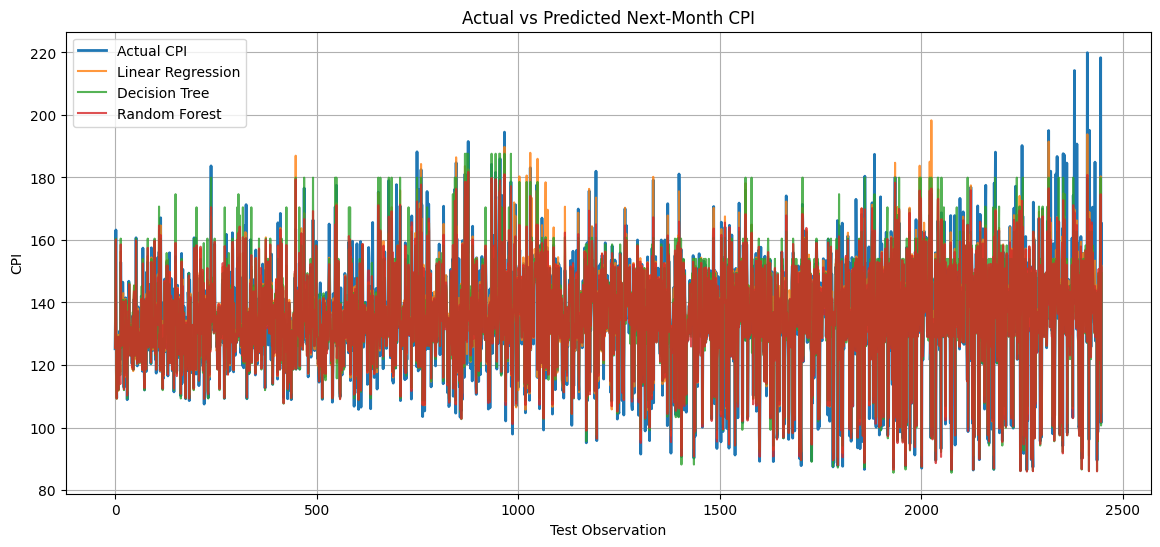

In [ ]:
# Compare actual vs predicted CPI

plt.figure(figsize=(14, 6))

plt.plot(
    y_test.values,
    label="Actual CPI",
    linewidth=2
)

plt.plot(
    y_pred_linear,
    label="Linear Regression",
    alpha=0.8
)

plt.plot(
    y_pred_tree,
    label="Decision Tree",
    alpha=0.8
)

plt.plot(
    y_pred_forest,
    label="Random Forest",
    alpha=0.8
)

plt.title("Actual vs Predicted Next-Month CPI")
plt.xlabel("Test Observation")
plt.ylabel("CPI")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Generate predictions on the training data

y_train_pred_linear = linear_model.predict(X_train)
y_train_pred_tree = tree_model.predict(X_train)
y_train_pred_forest = forest_model.predict(X_train)


# Function for evaluating training performance

def get_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R²": r2_score(y_true, y_pred)
    }


# Calculate training metrics

train_results = pd.DataFrame([
    {
        "Model": "Linear Regression",
        **get_metrics(y_train, y_train_pred_linear)
    },
    {
        "Model": "Decision Tree",
        **get_metrics(y_train, y_train_pred_tree)
    },
    {
        "Model": "Random Forest",
        **get_metrics(y_train, y_train_pred_forest)
    }
])

print("Training Performance:")
display(
    train_results.style.format({
        "MAE": "{:.4f}",
        "RMSE": "{:.4f}",
        "R²": "{:.4f}"
    })
)

Training Performance:


,Model,MAE,RMSE,R²
0,Linear Regression,1.9019,3.2622,0.9577
1,Decision Tree,1.5328,2.4708,0.9757
2,Random Forest,1.3935,2.4007,0.9771


In [ ]:
# Calculate train-test performance gaps

test_results = results_df.copy()

gap_df = train_results.merge(
    test_results,
    on="Model",
    suffixes=("_Train", "_Test")
)

gap_df["R²_Gap"] = (
    gap_df["R²_Train"] - gap_df["R²_Test"]
)

display(
    gap_df[
        [
            "Model",
            "R²_Train",
            "R²_Test",
            "R²_Gap"
        ]
    ].style.format({
        "R²_Train": "{:.4f}",
        "R²_Test": "{:.4f}",
        "R²_Gap": "{:.4f}"
    })
)

,Model,R²_Train,R²_Test,R²_Gap
0,Linear Regression,0.9577,0.9316,0.0261
1,Decision Tree,0.9757,0.9022,0.0735
2,Random Forest,0.9771,0.9288,0.0483


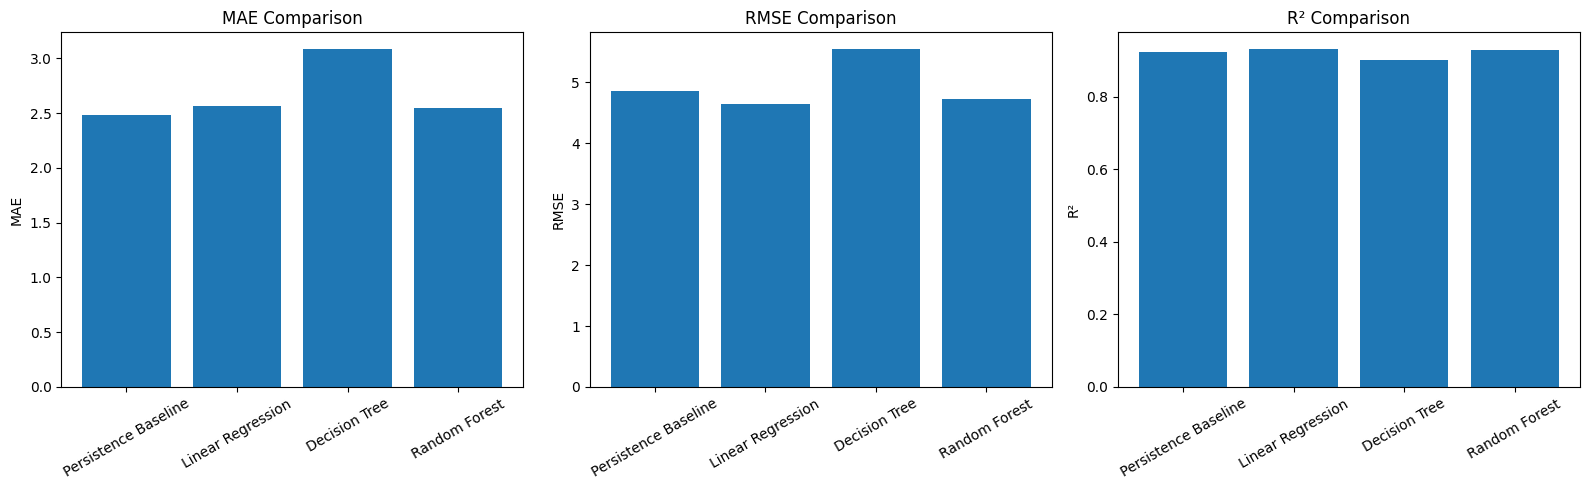

In [ ]:
# Plot model performance comparison

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# MAE
axes[0].bar(
    comparison_df["Model"],
    comparison_df["MAE"]
)
axes[0].set_title("MAE Comparison")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis="x", rotation=30)

# RMSE
axes[1].bar(
    comparison_df["Model"],
    comparison_df["RMSE"]
)
axes[1].set_title("RMSE Comparison")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis="x", rotation=30)

# R²
axes[2].bar(
    comparison_df["Model"],
    comparison_df["R²"]
)
axes[2].set_title("R² Comparison")
axes[2].set_ylabel("R²")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [ ]:
# Calculate prediction errors

error_df = pd.DataFrame({
    "Actual_CPI": y_test.values,
    "Linear_Prediction": y_pred_linear,
    "Tree_Prediction": y_pred_tree,
    "Forest_Prediction": y_pred_forest
})

error_df["Linear_Error"] = (
    error_df["Actual_CPI"] -
    error_df["Linear_Prediction"]
)

error_df["Tree_Error"] = (
    error_df["Actual_CPI"] -
    error_df["Tree_Prediction"]
)

error_df["Forest_Error"] = (
    error_df["Actual_CPI"] -
    error_df["Forest_Prediction"]
)

display(error_df.head(10))

,Actual_CPI,Linear_Prediction,Tree_Prediction,Forest_Prediction,Linear_Error,Tree_Error,Forest_Error
0,125.2,125.600921,125.536559,125.498376,-0.400921,-0.336559,-0.298376
1,137.1,138.081883,138.633333,138.226599,-0.981883,-1.533333,-1.126599
2,163.2,160.112234,160.433333,160.094450,3.087766,2.766667,3.105550
3,118.4,119.192782,120.551974,120.247504,-0.792782,-2.151974,-1.847504
4,109.4,109.211319,109.303211,109.355935,0.188681,0.096789,0.044065
5,128.5,128.607223,129.031061,128.757600,-0.107223,-0.531061,-0.257600
6,126.6,126.602854,127.222561,126.931075,-0.002854,-0.622561,-0.331075
7,128.2,129.577259,129.031061,128.862616,-1.377259,-0.831061,-0.662616
8,112.1,111.729523,111.957838,112.157048,0.370477,0.142162,-0.057048
9,125.9,128.322241,127.795890,128.741185,-2.422241,-1.895890,-2.841185


In [ ]:
# Calculate mean error for each model

mean_errors = {
    "Linear Regression": error_df["Linear_Error"].mean(),
    "Decision Tree": error_df["Tree_Error"].mean(),
    "Random Forest": error_df["Forest_Error"].mean()
}

print("Mean Prediction Error")
print("---------------------")

for model, error in mean_errors.items():
    print(f"{model}: {error:.4f}")

Mean Prediction Error
---------------------
Linear Regression: -0.1925
Decision Tree: 0.1608
Random Forest: 0.5545


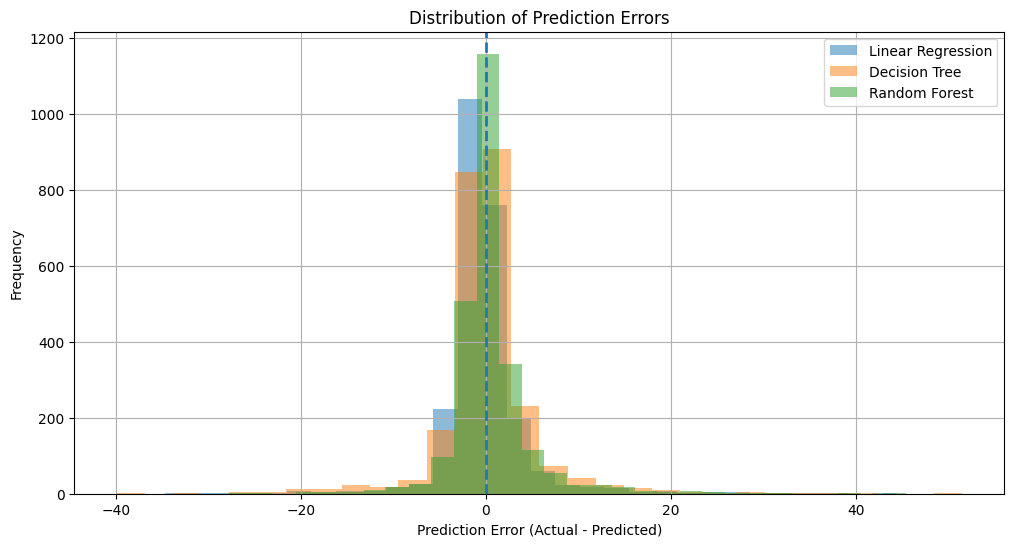

In [ ]:
# Plot prediction error distributions

plt.figure(figsize=(12, 6))

plt.hist(
    error_df["Linear_Error"],
    bins=30,
    alpha=0.5,
    label="Linear Regression"
)

plt.hist(
    error_df["Tree_Error"],
    bins=30,
    alpha=0.5,
    label="Decision Tree"
)

plt.hist(
    error_df["Forest_Error"],
    bins=30,
    alpha=0.5,
    label="Random Forest"
)

plt.axvline(
    0,
    linestyle="--",
    linewidth=2
)

plt.title("Distribution of Prediction Errors")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
# Find the largest absolute prediction errors

error_df["Linear_Abs_Error"] = error_df["Linear_Error"].abs()
error_df["Tree_Abs_Error"] = error_df["Tree_Error"].abs()
error_df["Forest_Abs_Error"] = error_df["Forest_Error"].abs()

# Show the 10 largest Linear Regression errors

largest_linear_errors = error_df.sort_values(
    "Linear_Abs_Error",
    ascending=False
).head(10)

display(
    largest_linear_errors[
        [
            "Actual_CPI",
            "Linear_Prediction",
            "Linear_Error",
            "Linear_Abs_Error"
        ]
    ]
)

,Actual_CPI,Linear_Prediction,Linear_Error,Linear_Abs_Error
2380,214.2,169.759692,44.440308,44.440308
2445,218.3,180.360967,37.939033,37.939033
1884,187.4,152.355913,35.044087,35.044087
1021,145.9,180.611698,-34.711698,34.711698
2431,184.9,153.389483,31.510517,31.510517
2361,184.6,153.166419,31.433581,31.433581
1899,173.8,142.511288,31.288712,31.288712
1068,148.0,178.450854,-30.450854,30.450854
1838,173.0,143.316434,29.683566,29.683566
1003,152.0,180.339018,-28.339018,28.339018


In [ ]:
# Add original information to the error dataframe

error_details = X_test[
    [
        "Geolocation",
        "Commodity_Code",
        "Commodity_Name",
        "CPI",
        "CPI_Lag_1",
        "CPI_Lag_2",
        "CPI_Lag_3"
    ]
].copy()

error_details["Actual_CPI"] = y_test.values
error_details["Linear_Prediction"] = y_pred_linear
error_details["Linear_Error"] = (
    error_details["Actual_CPI"]
    - error_details["Linear_Prediction"]
)
error_details["Absolute_Error"] = (
    error_details["Linear_Error"].abs()
)

largest_errors = error_details.sort_values(
    "Absolute_Error",
    ascending=False
).head(10)

display(largest_errors)

,Geolocation,Commodity_Code,Commodity_Name,CPI,CPI_Lag_1,CPI_Lag_2,CPI_Lag_3,Actual_CPI,Linear_Prediction,Linear_Error,Absolute_Error
12168,Region II (Cagayan Valley),01.1.7,Vegetables,169.9,170.9,161.0,162.5,214.2,169.759692,44.440308,44.440308
12233,Region VII (Central Visayas),01.1.7,Vegetables,177.2,166.5,166.1,164.6,218.3,180.360967,37.939033,37.939033
11672,National Capital Region (NCR),01.1.7,Vegetables,149.1,140.4,141.4,135.6,187.4,152.355913,35.044087,35.044087
10809,Region I (Ilocos Region),01.1.7,Vegetables,184.2,175.5,156.2,146.3,145.9,180.611698,-34.711698,34.711698
12219,Region III (Central Luzon),01.1.7,Vegetables,155.3,167.8,161.7,165.4,184.9,153.389483,31.510517,31.510517
12149,Region V (Bicol Region),01.1.7,Vegetables,151.4,152.8,152.1,152.5,184.6,153.166419,31.433581,31.433581
11687,Region I (Ilocos Region),01.1.7,Vegetables,139.9,135.1,137.6,130.2,173.8,142.511288,31.288712,31.288712
10856,Region III (Central Luzon),01.1.7,Vegetables,181.6,170.8,157.6,142.8,148.0,178.450854,-30.450854,30.450854
11626,Region IV-A (CALABARZON),01.1.7,Vegetables,140.5,134.9,137.3,130.0,173.0,143.316434,29.683566,29.683566
10791,Region IV-A (CALABARZON),01.1.7,Vegetables,186.0,176.3,165.6,141.9,152.0,180.339018,-28.339018,28.339018


In [ ]:
# Display the largest prediction errors with their details

display(
    largest_errors[
        [
            "Geolocation",
            "Commodity_Code",
            "Commodity_Name",
            "CPI",
            "CPI_Lag_1",
            "CPI_Lag_2",
            "CPI_Lag_3",
            "Actual_CPI",
            "Linear_Prediction",
            "Linear_Error",
            "Absolute_Error"
        ]
    ]
)

,Geolocation,Commodity_Code,Commodity_Name,CPI,CPI_Lag_1,CPI_Lag_2,CPI_Lag_3,Actual_CPI,Linear_Prediction,Linear_Error,Absolute_Error
12168,Region II (Cagayan Valley),01.1.7,Vegetables,169.9,170.9,161.0,162.5,214.2,169.759692,44.440308,44.440308
12233,Region VII (Central Visayas),01.1.7,Vegetables,177.2,166.5,166.1,164.6,218.3,180.360967,37.939033,37.939033
11672,National Capital Region (NCR),01.1.7,Vegetables,149.1,140.4,141.4,135.6,187.4,152.355913,35.044087,35.044087
10809,Region I (Ilocos Region),01.1.7,Vegetables,184.2,175.5,156.2,146.3,145.9,180.611698,-34.711698,34.711698
12219,Region III (Central Luzon),01.1.7,Vegetables,155.3,167.8,161.7,165.4,184.9,153.389483,31.510517,31.510517
12149,Region V (Bicol Region),01.1.7,Vegetables,151.4,152.8,152.1,152.5,184.6,153.166419,31.433581,31.433581
11687,Region I (Ilocos Region),01.1.7,Vegetables,139.9,135.1,137.6,130.2,173.8,142.511288,31.288712,31.288712
10856,Region III (Central Luzon),01.1.7,Vegetables,181.6,170.8,157.6,142.8,148.0,178.450854,-30.450854,30.450854
11626,Region IV-A (CALABARZON),01.1.7,Vegetables,140.5,134.9,137.3,130.0,173.0,143.316434,29.683566,29.683566
10791,Region IV-A (CALABARZON),01.1.7,Vegetables,186.0,176.3,165.6,141.9,152.0,180.339018,-28.339018,28.339018


In [ ]:
# Check CPI distribution in the test set

print("Test CPI statistics:")
display(
    X_test["CPI"].describe()
)

print("\nLargest CPI values in the test set:")
display(
    X_test[
        [
            "Geolocation",
            "Commodity_Name",
            "CPI"
        ]
    ]
    .sort_values("CPI", ascending=False)
    .head(10)
)

Test CPI statistics:


,CPI
count,2448.000000
mean,135.429575
std,16.850597
min,86.300000
25%,127.300000
50%,134.700000
75%,146.500000
max,194.500000



Largest CPI values in the test set:


,Geolocation,Commodity_Name,CPI
10836,Region II (Cagayan Valley),Vegetables,194.5
10818,Negros Island Region (NIR),Vegetables,191.5
12200,Negros Island Region (NIR),Vegetables,190.2
10754,Region II (Cagayan Valley),Vegetables,188.2
12104,National Capital Region (NCR),Vegetables,188.1
11813,National Capital Region (NCR),Vegetables,187.4
10791,Region IV-A (CALABARZON),Vegetables,186.0
10656,National Capital Region (NCR),Vegetables,184.7
10809,Region I (Ilocos Region),Vegetables,184.2
10236,Negros Island Region (NIR),Vegetables,183.7


In [ ]:
# Check the largest CPI changes in the test set

test_change_check = X_test[
    [
        "Geolocation",
        "Commodity_Name",
        "CPI",
        "CPI_Lag_1",
        "CPI_Change",
        "CPI_Pct_Change"
    ]
].copy()

test_change_check["Target_CPI"] = y_test.values

test_change_check["Absolute_Change"] = (
    test_change_check["CPI_Change"].abs()
)

largest_changes = test_change_check.sort_values(
    "Absolute_Change",
    ascending=False
).head(10)

display(largest_changes)

,Geolocation,Commodity_Name,CPI,CPI_Lag_1,CPI_Change,CPI_Pct_Change,Target_CPI,Absolute_Change
11813,National Capital Region (NCR),Vegetables,187.4,149.1,38.3,0.256875,174.7,38.3
10912,Region I (Ilocos Region),Vegetables,145.9,184.2,-38.3,-0.207926,137.1,38.3
10979,Region II (Cagayan Valley),Vegetables,160.4,194.5,-34.1,-0.175321,141.6,34.1
10988,Region IV-A (CALABARZON),Vegetables,152.0,186.0,-34.0,-0.182796,139.0,34.0
11809,Region I (Ilocos Region),Vegetables,173.8,139.9,33.9,0.242316,167.9,33.9
10958,Region III (Central Luzon),Vegetables,148.0,181.6,-33.6,-0.185022,132.0,33.6
11784,Region IV-A (CALABARZON),Vegetables,173.0,140.5,32.5,0.231317,165.8,32.5
10999,National Capital Region (NCR),Vegetables,150.3,181.1,-30.8,-0.170072,139.3,30.8
11830,Region III (Central Luzon),Vegetables,165.4,134.8,30.6,0.227003,161.7,30.6
10567,Region V (Bicol Region),Vegetables,154.1,125.9,28.2,0.223987,155.2,28.2


In [ ]:
# Calculate absolute prediction error for each test observation

commodity_errors = X_test[
    ["Geolocation", "Commodity_Code", "Commodity_Name"]
].copy()

commodity_errors["Actual_CPI"] = y_test.values
commodity_errors["Predicted_CPI"] = y_pred_linear

commodity_errors["Absolute_Error"] = (
    commodity_errors["Actual_CPI"]
    - commodity_errors["Predicted_CPI"]
).abs()

# Average error by commodity

commodity_summary = (
    commodity_errors
    .groupby("Commodity_Name")["Absolute_Error"]
    .agg(["mean", "count"])
    .sort_values("mean", ascending=False)
)

commodity_summary.columns = [
    "Mean_Absolute_Error",
    "Number_of_Observations"
]

display(
    commodity_summary.head(15)
)

,Mean_Absolute_Error,Number_of_Observations
Commodity_Name,,
Vegetables,7.430374,351
Rice,2.490325,350
Fruits,2.430589,352
Fish & Seafood,1.921788,346
Meat,1.525442,346
Food,1.164998,352
Dairy & Eggs,1.009503,351


In [ ]:
# Calculate absolute errors for all three models

commodity_comparison = X_test[
    ["Commodity_Name"]
].copy()

commodity_comparison["Linear_Error"] = np.abs(
    y_test.values - y_pred_linear
)

commodity_comparison["Tree_Error"] = np.abs(
    y_test.values - y_pred_tree
)

commodity_comparison["Forest_Error"] = np.abs(
    y_test.values - y_pred_forest
)


# Average absolute error by commodity

commodity_model_summary = (
    commodity_comparison
    .groupby("Commodity_Name")
    .agg(
        Linear_MAE=("Linear_Error", "mean"),
        Tree_MAE=("Tree_Error", "mean"),
        Random_Forest_MAE=("Forest_Error", "mean")
    )
    .sort_values("Linear_MAE", ascending=False)
)

display(
    commodity_model_summary.head(15)
)

,Linear_MAE,Tree_MAE,Random_Forest_MAE
Commodity_Name,,,
Vegetables,7.430374,8.727082,7.629880
Rice,2.490325,2.216902,1.982466
Fruits,2.430589,4.339665,2.995065
Fish & Seafood,1.921788,2.075613,1.870821
Meat,1.525442,2.073724,1.612939
Food,1.164998,1.179386,1.005364
Dairy & Eggs,1.009503,0.949250,0.723853


In [ ]:
# Find the best-performing model for each commodity

commodity_model_summary["Best_Model"] = (
    commodity_model_summary[
        [
            "Linear_MAE",
            "Tree_MAE",
            "Random_Forest_MAE"
        ]
    ]
    .idxmin(axis=1)
    .str.replace("_MAE", "", regex=False)
)

display(commodity_model_summary.head(15))

,Linear_MAE,Tree_MAE,Random_Forest_MAE,Best_Model
Commodity_Name,,,,
Vegetables,7.430374,8.727082,7.629880,Linear
Rice,2.490325,2.216902,1.982466,Random_Forest
Fruits,2.430589,4.339665,2.995065,Linear
Fish & Seafood,1.921788,2.075613,1.870821,Random_Forest
Meat,1.525442,2.073724,1.612939,Linear
Food,1.164998,1.179386,1.005364,Random_Forest
Dairy & Eggs,1.009503,0.949250,0.723853,Random_Forest


In [ ]:
# Calculate absolute errors for all three models

location_comparison = X_test[
    ["Geolocation"]
].copy()

location_comparison["Linear_Error"] = np.abs(
    y_test.values - y_pred_linear
)

location_comparison["Tree_Error"] = np.abs(
    y_test.values - y_pred_tree
)

location_comparison["Forest_Error"] = np.abs(
    y_test.values - y_pred_forest
)

# Average MAE by location

location_model_summary = (
    location_comparison
    .groupby("Geolocation")
    .agg(
        Linear_MAE=("Linear_Error", "mean"),
        Tree_MAE=("Tree_Error", "mean"),
        Random_Forest_MAE=("Forest_Error", "mean")
    )
    .sort_values("Linear_MAE", ascending=False)
)

display(location_model_summary)

,Linear_MAE,Tree_MAE,Random_Forest_MAE
Geolocation,,,
Region I (Ilocos Region),3.554261,3.915078,3.414952
Region II (Cagayan Valley),3.426422,3.741238,3.426379
Region III (Central Luzon),3.348698,4.198143,3.425477
Region VII (Central Visayas),3.055148,3.935368,3.289390
Region IV-A (CALABARZON),3.048115,3.556151,2.809052
Region V (Bicol Region),2.912191,3.019715,2.939448
National Capital Region (NCR),2.665813,3.268138,2.796327
Negros Island Region (NIR),2.633541,2.817712,2.447587
Region XII (SOCCSKSARGEN),2.509929,3.199671,2.445120


In [ ]:
# Find the best model for each location

location_model_summary["Best_Model"] = (
    location_model_summary[
        [
            "Linear_MAE",
            "Tree_MAE",
            "Random_Forest_MAE"
        ]
    ]
    .idxmin(axis=1)
    .str.replace("_MAE", "", regex=False)
)

display(location_model_summary)

,Linear_MAE,Tree_MAE,Random_Forest_MAE,Best_Model
Geolocation,,,,
Region I (Ilocos Region),3.554261,3.915078,3.414952,Random_Forest
Region II (Cagayan Valley),3.426422,3.741238,3.426379,Random_Forest
Region III (Central Luzon),3.348698,4.198143,3.425477,Linear
Region VII (Central Visayas),3.055148,3.935368,3.289390,Linear
Region IV-A (CALABARZON),3.048115,3.556151,2.809052,Random_Forest
Region V (Bicol Region),2.912191,3.019715,2.939448,Linear
National Capital Region (NCR),2.665813,3.268138,2.796327,Linear
Negros Island Region (NIR),2.633541,2.817712,2.447587,Random_Forest
Region XII (SOCCSKSARGEN),2.509929,3.199671,2.445120,Random_Forest


In [ ]:
# Save overall model comparison

comparison_df.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model comparison saved successfully!")

display(comparison_df)

Model comparison saved successfully!


,Model,MAE,RMSE,R²
0,Persistence Baseline,2.484763,4.865309,0.924690
1,Linear Regression,2.570424,4.637335,0.931582
2,Decision Tree,3.084430,5.543855,0.902218
3,Random Forest,2.548838,4.730152,0.928816


In [ ]:
# Save commodity-level comparison

commodity_model_summary.to_csv(
    "commodity_model_comparison.csv"
)

print("Commodity comparison saved successfully!")

Commodity comparison saved successfully!


In [ ]:
# Save location-level comparison

location_model_summary.to_csv(
    "location_model_comparison.csv"
)

print("Location comparison saved successfully!")

Location comparison saved successfully!


In [ ]:
# Import joblib
import joblib

# Save the trained model pipelines

joblib.dump(
    linear_model,
    "linear_regression_pipeline.pkl"
)

joblib.dump(
    tree_model,
    "decision_tree_pipeline.pkl"
)

joblib.dump(
    forest_model,
    "random_forest_pipeline.pkl"
)

print("All 3 trained model pipelines saved successfully!")

All 3 trained model pipelines saved successfully!


In [ ]:
# Persistence baseline
# Predict next month's CPI using the current month's CPI

y_pred_baseline = X_test["CPI"]

baseline_mae = mean_absolute_error(y_test, y_pred_baseline)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred_baseline))
baseline_r2 = r2_score(y_test, y_pred_baseline)

print("Persistence Baseline")
print(f"MAE:  {baseline_mae:.4f}")
print(f"RMSE: {baseline_rmse:.4f}")
print(f"R²:   {baseline_r2:.4f}")

Persistence Baseline
MAE:  2.4848
RMSE: 4.8653
R²:   0.9247


In [ ]:
print("\nModel Comparison")

comparison_df = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        mean_absolute_error(y_test, y_pred_linear),
        mean_absolute_error(y_test, y_pred_tree),
        mean_absolute_error(y_test, y_pred_forest)
    ],
    "RMSE": [
        baseline_rmse,
        np.sqrt(mean_squared_error(y_test, y_pred_linear)),
        np.sqrt(mean_squared_error(y_test, y_pred_tree)),
        np.sqrt(mean_squared_error(y_test, y_pred_forest))
    ],
    "R²": [
        baseline_r2,
        r2_score(y_test, y_pred_linear),
        r2_score(y_test, y_pred_tree),
        r2_score(y_test, y_pred_forest)
    ]
})

comparison_df


Model Comparison


,Model,MAE,RMSE,R²
0,Persistence Baseline,2.484763,4.865309,0.924690
1,Linear Regression,2.570424,4.637335,0.931582
2,Decision Tree,3.084430,5.543855,0.902218
3,Random Forest,2.548838,4.730152,0.928816


In [ ]:
from sklearn.model_selection import TimeSeriesSplit

tscv = TimeSeriesSplit(n_splits=3)

models = {
    "Linear Regression": linear_model,
    "Decision Tree": tree_model,
    "Random Forest": forest_model
}

validation_results = []

for model_name, model in models.items():

    fold_mae = []
    fold_rmse = []
    fold_r2 = []

    for train_idx, val_idx in tscv.split(X_train):

        X_tr = X_train.iloc[train_idx]
        X_val = X_train.iloc[val_idx]

        y_tr = y_train.iloc[train_idx]
        y_val = y_train.iloc[val_idx]

        # Train model on this fold
        model.fit(X_tr, y_tr)

        # Predict validation data
        y_val_pred = model.predict(X_val)

        # Metrics
        fold_mae.append(mean_absolute_error(y_val, y_val_pred))
        fold_rmse.append(
            np.sqrt(mean_squared_error(y_val, y_val_pred))
        )
        fold_r2.append(r2_score(y_val, y_val_pred))

    validation_results.append({
        "Model": model_name,
        "Mean MAE": np.mean(fold_mae),
        "Mean RMSE": np.mean(fold_rmse),
        "Mean R²": np.mean(fold_r2)
    })

validation_df = pd.DataFrame(validation_results)

validation_df

,Model,Mean MAE,Mean RMSE,Mean R²
0,Linear Regression,2.272292,3.900466,0.909765
1,Decision Tree,3.158654,5.434113,0.830019
2,Random Forest,2.506847,4.700886,0.870575


In [ ]:
# Retrain final models using the complete training set

linear_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

print("All final models have been retrained.")

All final models have been retrained.


In [ ]:
import joblib
import os

os.makedirs("models", exist_ok=True)

# Retrain the three models
linear_model.fit(X_train, y_train)
tree_model.fit(X_train, y_train)
forest_model.fit(X_train, y_train)

# Save the fitted pipelines
joblib.dump(linear_model, "models/linear_regression_pipeline.pkl")
joblib.dump(tree_model, "models/decision_tree_pipeline.pkl")
joblib.dump(forest_model, "models/random_forest_pipeline.pkl")

print("All three models were saved successfully!")

All three models were saved successfully!


In [ ]:
# Final predictions on the untouched test set

y_pred_linear_final = linear_model.predict(X_test)
y_pred_tree_final = tree_model.predict(X_test)
y_pred_forest_final = forest_model.predict(X_test)

# Calculate final metrics
final_results = pd.DataFrame({
    "Model": [
        "Persistence Baseline",
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        baseline_mae,
        mean_absolute_error(y_test, y_pred_linear_final),
        mean_absolute_error(y_test, y_pred_tree_final),
        mean_absolute_error(y_test, y_pred_forest_final)
    ],
    "RMSE": [
        baseline_rmse,
        np.sqrt(mean_squared_error(y_test, y_pred_linear_final)),
        np.sqrt(mean_squared_error(y_test, y_pred_tree_final)),
        np.sqrt(mean_squared_error(y_test, y_pred_forest_final))
    ],
    "R²": [
        baseline_r2,
        r2_score(y_test, y_pred_linear_final),
        r2_score(y_test, y_pred_tree_final),
        r2_score(y_test, y_pred_forest_final)
    ]
})

final_results.round(4)

,Model,MAE,RMSE,R²
0,Persistence Baseline,2.4848,4.8653,0.9247
1,Linear Regression,2.5704,4.6373,0.9316
2,Decision Tree,3.0844,5.5439,0.9022
3,Random Forest,2.5488,4.7302,0.9288


In [ ]:
import joblib
import os

# Create models folder
os.makedirs("models", exist_ok=True)

# Save final trained pipelines
joblib.dump(
    linear_model,
    "models/linear_regression_pipeline.pkl"
)

joblib.dump(
    tree_model,
    "models/decision_tree_pipeline.pkl"
)

joblib.dump(
    forest_model,
    "models/random_forest_pipeline.pkl"
)

print("Final models saved successfully!")
# Record the package version used to create these saved models
with open("models/model_environment.txt", "w", encoding="utf-8") as f:
    f.write(f"scikit-learn=={sklearn.__version__}\n")
print("Model environment recorded:", sklearn.__version__)


Final models saved successfully!
Model environment recorded: 1.8.0


In [ ]:
os.listdir("models")

['random_forest_pipeline.pkl',
 'linear_regression_pipeline.pkl',
 'decision_tree_pipeline.pkl',
 'model_environment.txt']

In [ ]:
# Create results folder
os.makedirs("results", exist_ok=True)

# Save final model comparison
final_results.to_csv(
    "results/final_model_comparison.csv",
    index=False
)

print("Final model comparison saved successfully!")

Final model comparison saved successfully!


In [ ]:
print(pd.read_csv("results/final_model_comparison.csv"))

                  Model       MAE      RMSE        R²
0  Persistence Baseline  2.484763  4.865309  0.924690
1     Linear Regression  2.570424  4.637335  0.931582
2         Decision Tree  3.084430  5.543855  0.902218
3         Random Forest  2.548838  4.730152  0.928816


In [ ]:
validation_df.to_csv(
    "results/validation_results.csv",
    index=False
)

print("Validation results saved successfully!")

Validation results saved successfully!


In [ ]:
# Example input
current_cpi = 150
lag_1 = 148
lag_2 = 147
lag_3 = 146
month = 10

quarter = (month - 1) // 3 + 1

cpi_change = current_cpi - lag_1

cpi_pct_change = (current_cpi - lag_1) / lag_1

rolling_mean_3 = np.mean([lag_1, lag_2, lag_3])

rolling_std_3 = np.std(
    [lag_1, lag_2, lag_3],
    ddof=1
)

month_sin = np.sin(2 * np.pi * month / 12)
month_cos = np.cos(2 * np.pi * month / 12)

def get_weather_season(month):
    if month in [12, 1, 2]:
        return "Cool_Dry"
    elif month in [3, 4, 5]:
        return "Hot_Dry"
    elif month in [6, 7, 8]:
        return "Rainy"
    else:
        return "Rainy_Transition"

weather_season = get_weather_season(month)

print("Quarter:", quarter)
print("CPI Change:", cpi_change)
print("CPI % Change:", cpi_pct_change)
print("3-Month Rolling Mean:", rolling_mean_3)
print("3-Month Rolling Std:", rolling_std_3)
print("Month Sin:", month_sin)
print("Month Cos:", month_cos)
print("Weather Season:", weather_season)

Quarter: 4
CPI Change: 2
CPI % Change: 0.013513513513513514
3-Month Rolling Mean: 147.0
3-Month Rolling Std: 1.0
Month Sin: -0.8660254037844386
Month Cos: 0.5000000000000001
Weather Season: Rainy_Transition


In [ ]:
def prepare_prediction_input(
    geolocation,
    commodity_code,
    commodity_name,
    year,
    month,
    current_cpi,
    cpi_lag_1,
    cpi_lag_2,
    cpi_lag_3
):

    # Quarter
    quarter = (month - 1) // 3 + 1

    # CPI change
    cpi_change = current_cpi - cpi_lag_1

    # CPI percentage change
    cpi_pct_change = (current_cpi - cpi_lag_1) / cpi_lag_1

    # 3-month rolling statistics
    previous_cpis = [
        cpi_lag_1,
        cpi_lag_2,
        cpi_lag_3
    ]

    rolling_mean_3 = np.mean(previous_cpis)

    rolling_std_3 = np.std(
        previous_cpis,
        ddof=1
    )

    # Seasonal features
    month_sin = np.sin(
        2 * np.pi * month / 12
    )

    month_cos = np.cos(
        2 * np.pi * month / 12
    )

    # Weather season
    weather_season = get_weather_season(month)

    # Create DataFrame
    prediction_input = pd.DataFrame([{
        "Geolocation": geolocation,
        "Commodity_Code": commodity_code,
        "Commodity_Name": commodity_name,
        "CPI": current_cpi,
        "Year": year,
        "Month": month,
        "Quarter": quarter,
        "CPI_Lag_1": cpi_lag_1,
        "CPI_Lag_2": cpi_lag_2,
        "CPI_Lag_3": cpi_lag_3,
        "CPI_Change": cpi_change,
        "CPI_Pct_Change": cpi_pct_change,
        "CPI_Rolling_Mean_3": rolling_mean_3,
        "CPI_Rolling_Std_3": rolling_std_3,
        "Month_Sin": month_sin,
        "Month_Cos": month_cos,
        "Weather_Season": weather_season
    }])

    return prediction_input

In [ ]:
test_input = prepare_prediction_input(
    geolocation="National Capital Region",
    commodity_code="TEST",
    commodity_name="Food",
    year=2026,
    month=10,
    current_cpi=150,
    cpi_lag_1=148,
    cpi_lag_2=147,
    cpi_lag_3=146
)

test_input

,Geolocation,Commodity_Code,Commodity_Name,CPI,Year,Month,Quarter,CPI_Lag_1,CPI_Lag_2,CPI_Lag_3,CPI_Change,CPI_Pct_Change,CPI_Rolling_Mean_3,CPI_Rolling_Std_3,Month_Sin,Month_Cos,Weather_Season
0,National Capital Region,TEST,Food,150,2026,10,4,148,147,146,2,0.013514,147.0,1.0,-0.866025,0.5,Rainy_Transition


In [ ]:
print(test_input.columns.tolist())
print()
print(test_input.iloc[0].to_dict())

['Geolocation', 'Commodity_Code', 'Commodity_Name', 'CPI', 'Year', 'Month', 'Quarter', 'CPI_Lag_1', 'CPI_Lag_2', 'CPI_Lag_3', 'CPI_Change', 'CPI_Pct_Change', 'CPI_Rolling_Mean_3', 'CPI_Rolling_Std_3', 'Month_Sin', 'Month_Cos', 'Weather_Season']

{'Geolocation': 'National Capital Region', 'Commodity_Code': 'TEST', 'Commodity_Name': 'Food', 'CPI': 150, 'Year': 2026, 'Month': 10, 'Quarter': 4, 'CPI_Lag_1': 148, 'CPI_Lag_2': 147, 'CPI_Lag_3': 146, 'CPI_Change': 2, 'CPI_Pct_Change': 0.013513513513513514, 'CPI_Rolling_Mean_3': 147.0, 'CPI_Rolling_Std_3': 1.0, 'Month_Sin': -0.8660254037844386, 'Month_Cos': 0.5000000000000001, 'Weather_Season': 'Rainy_Transition'}


In [ ]:
# Generate predictions from all three models

linear_prediction = linear_model.predict(test_input)[0]
tree_prediction = tree_model.predict(test_input)[0]
forest_prediction = forest_model.predict(test_input)[0]

print("Linear Regression Prediction:", linear_prediction)
print("Decision Tree Prediction:", tree_prediction)
print("Random Forest Prediction:", forest_prediction)

Linear Regression Prediction: 151.17510178737257
Decision Tree Prediction: 149.39499999999998
Random Forest Prediction: 150.73525681881287


In [ ]:
prediction_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Predicted_Next_Month_CPI": [
        linear_prediction,
        tree_prediction,
        forest_prediction
    ]
})

prediction_comparison

,Model,Predicted_Next_Month_CPI
0,Linear Regression,151.175102
1,Decision Tree,149.395000
2,Random Forest,150.735257


In [ ]:
prediction_code = '''
import numpy as np
import pandas as pd

def get_weather_season(month):
    if month in [12, 1, 2]:
        return "Cool_Dry"
    elif month in [3, 4, 5]:
        return "Hot_Dry"
    elif month in [6, 7, 8]:
        return "Rainy"
    else:
        return "Rainy_Transition"


def prepare_prediction_input(
    geolocation,
    commodity_code,
    commodity_name,
    year,
    month,
    current_cpi,
    cpi_lag_1,
    cpi_lag_2,
    cpi_lag_3
):

    quarter = (month - 1) // 3 + 1

    cpi_change = current_cpi - cpi_lag_1

    cpi_pct_change = (
        (current_cpi - cpi_lag_1) / cpi_lag_1
    )

    previous_cpis = [
        cpi_lag_1,
        cpi_lag_2,
        cpi_lag_3
    ]

    rolling_mean_3 = np.mean(previous_cpis)

    rolling_std_3 = np.std(
        previous_cpis,
        ddof=1
    )

    month_sin = np.sin(
        2 * np.pi * month / 12
    )

    month_cos = np.cos(
        2 * np.pi * month / 12
    )

    weather_season = get_weather_season(month)

    prediction_input = pd.DataFrame([{
        "Geolocation": geolocation,
        "Commodity_Code": commodity_code,
        "Commodity_Name": commodity_name,
        "CPI": current_cpi,
        "Year": year,
        "Month": month,
        "Quarter": quarter,
        "CPI_Lag_1": cpi_lag_1,
        "CPI_Lag_2": cpi_lag_2,
        "CPI_Lag_3": cpi_lag_3,
        "CPI_Change": cpi_change,
        "CPI_Pct_Change": cpi_pct_change,
        "CPI_Rolling_Mean_3": rolling_mean_3,
        "CPI_Rolling_Std_3": rolling_std_3,
        "Month_Sin": month_sin,
        "Month_Cos": month_cos,
        "Weather_Season": weather_season
    }])

    return prediction_input
'''

with open("prediction_utils.py", "w") as f:
    f.write(prediction_code)

print("prediction_utils.py created successfully!")

prediction_utils.py created successfully!


In [ ]:
import os
print(os.path.exists("prediction_utils.py"))

True


In [ ]:
import shutil
import os

# Create project folders
os.makedirs("ML_CPI_Project/models", exist_ok=True)
os.makedirs("ML_CPI_Project/results", exist_ok=True)
os.makedirs("ML_CPI_Project/data", exist_ok=True)

# Copy trained models
shutil.copy(
    "models/linear_regression_pipeline.pkl",
    "ML_CPI_Project/models/linear_regression_pipeline.pkl"
)

shutil.copy(
    "models/decision_tree_pipeline.pkl",
    "ML_CPI_Project/models/decision_tree_pipeline.pkl"
)

shutil.copy(
    "models/random_forest_pipeline.pkl",
    "ML_CPI_Project/models/random_forest_pipeline.pkl"
)

# Copy results
shutil.copy(
    "results/final_model_comparison.csv",
    "ML_CPI_Project/results/final_model_comparison.csv"
)

shutil.copy(
    "results/validation_results.csv",
    "ML_CPI_Project/results/validation_results.csv"
)

# Copy prediction utility
shutil.copy(
    "prediction_utils.py",
    "ML_CPI_Project/prediction_utils.py"
)

# Copy dataset
shutil.copy(
    "MLDST_Final_Cleaned.csv",
    "ML_CPI_Project/data/MLDST_Final_Cleaned.csv"
)

print("Project files prepared successfully!")

Project files prepared successfully!


In [ ]:
for root, dirs, files in os.walk("ML_CPI_Project"):
    level = root.replace("ML_CPI_Project", "").count(os.sep)
    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

ML_CPI_Project/
    prediction_utils.py
    results/
        validation_results.csv
        final_model_comparison.csv
    data/
        MLDST_Final_Cleaned.csv
    models/
        random_forest_pipeline.pkl
        linear_regression_pipeline.pkl
        decision_tree_pipeline.pkl


In [ ]:
import shutil

shutil.make_archive(
    "ML_CPI_Project",
    "zip",
    "ML_CPI_Project"
)

print("ML_CPI_Project.zip created!")

ML_CPI_Project.zip created!


In [ ]:
from google.colab import files

files.download("ML_CPI_Project.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn
import sys

print("Python version:", sys.version)
print("Scikit-learn version:", sklearn.__version__)

Python version: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Scikit-learn version: 1.8.0


In [ ]:
from google.colab import files

files.download("models/linear_regression_pipeline.pkl")
files.download("models/decision_tree_pipeline.pkl")
files.download("models/random_forest_pipeline.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn
print("Scikit-learn version:", sklearn.__version__)
print("Linear model exists:", "linear_model" in globals())
print("Decision tree exists:", "tree_model" in globals())
print("Random forest exists:", "forest_model" in globals())

Scikit-learn version: 1.8.0
Linear model exists: True
Decision tree exists: True
Random forest exists: True


In [ ]:
import os
import joblib
import zipfile

os.makedirs("models_fixed", exist_ok=True)

# Save the three trained pipelines
joblib.dump(linear_model, "models_fixed/linear_regression_pipeline.pkl")
joblib.dump(tree_model, "models_fixed/decision_tree_pipeline.pkl")
joblib.dump(forest_model, "models_fixed/random_forest_pipeline.pkl")

# Package the models into one ZIP file
with zipfile.ZipFile("fixed_models.zip", "w", zipfile.ZIP_DEFLATED) as z:
    z.write(
        "models_fixed/linear_regression_pipeline.pkl",
        "linear_regression_pipeline.pkl"
    )
    z.write(
        "models_fixed/decision_tree_pipeline.pkl",
        "decision_tree_pipeline.pkl"
    )
    z.write(
        "models_fixed/random_forest_pipeline.pkl",
        "random_forest_pipeline.pkl"
    )

print("Saved all three models.")
print("Scikit-learn version:", sklearn.__version__)
print("ZIP file created: fixed_models.zip")

Saved all three models.
Scikit-learn version: 1.8.0
ZIP file created: fixed_models.zip


In [ ]:
from google.colab import files
files.download("fixed_models.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import sklearn
import joblib
import os

print("Scikit-learn version:", sklearn.__version__)

model_files = [
    "models/linear_regression_pipeline.pkl",
    "models/decision_tree_pipeline.pkl",
    "models/random_forest_pipeline.pkl"
]

for path in model_files:
    print(path, "—", "Found" if os.path.exists(path) else "MISSING")

# Test that the saved models can be loaded
for path in model_files:
    model = joblib.load(path)
    print("Loaded successfully:", os.path.basename(path))

Scikit-learn version: 1.8.0
models/linear_regression_pipeline.pkl — Found
models/decision_tree_pipeline.pkl — Found
models/random_forest_pipeline.pkl — Found
Loaded successfully: linear_regression_pipeline.pkl
Loaded successfully: decision_tree_pipeline.pkl
Loaded successfully: random_forest_pipeline.pkl


In [ ]:
from google.colab import files
import zipfile

with zipfile.ZipFile("models_compatible.zip", "w") as z:
    z.write("models/linear_regression_pipeline.pkl",
            "linear_regression_pipeline.pkl")
    z.write("models/decision_tree_pipeline.pkl",
            "decision_tree_pipeline.pkl")
    z.write("models/random_forest_pipeline.pkl",
            "random_forest_pipeline.pkl")

files.download("models_compatible.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>